In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [5]:
data = {
    "Study_Hours":[1,2,3,4,5,6],
    "Attendance":[50,60,65,70,80,85],
    "Result":[
        "Fail", "Fail", "Fail",
        "Pass", "Pass", "Pass"
    ]
}
df = pd.DataFrame(data)
print("Student Dataset")

Student Dataset


In [6]:
x=df[["Study_Hours","Attendance"]]
y=df["Result"] 

In [7]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [8]:
print("\nTraining Records")
print(len(x_train))


Training Records
4


In [9]:
print("\nTesting Records")
print(len(x_test))


Testing Records
2


In [10]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=2,
    random_state=42
)

In [11]:
model.fit(x_train, y_train)
print("\nDecision Tree Model Trained Successfully")


Decision Tree Model Trained Successfully


[Text(0.5, 0.75, 'Study_Hours <= 3.5\ngini = 0.5\nsamples = 4\nvalue = [2, 2]\nclass = Fail'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]\nclass = Fail'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]\nclass = Pass'),
 Text(0.625, 0.5, '  False')]

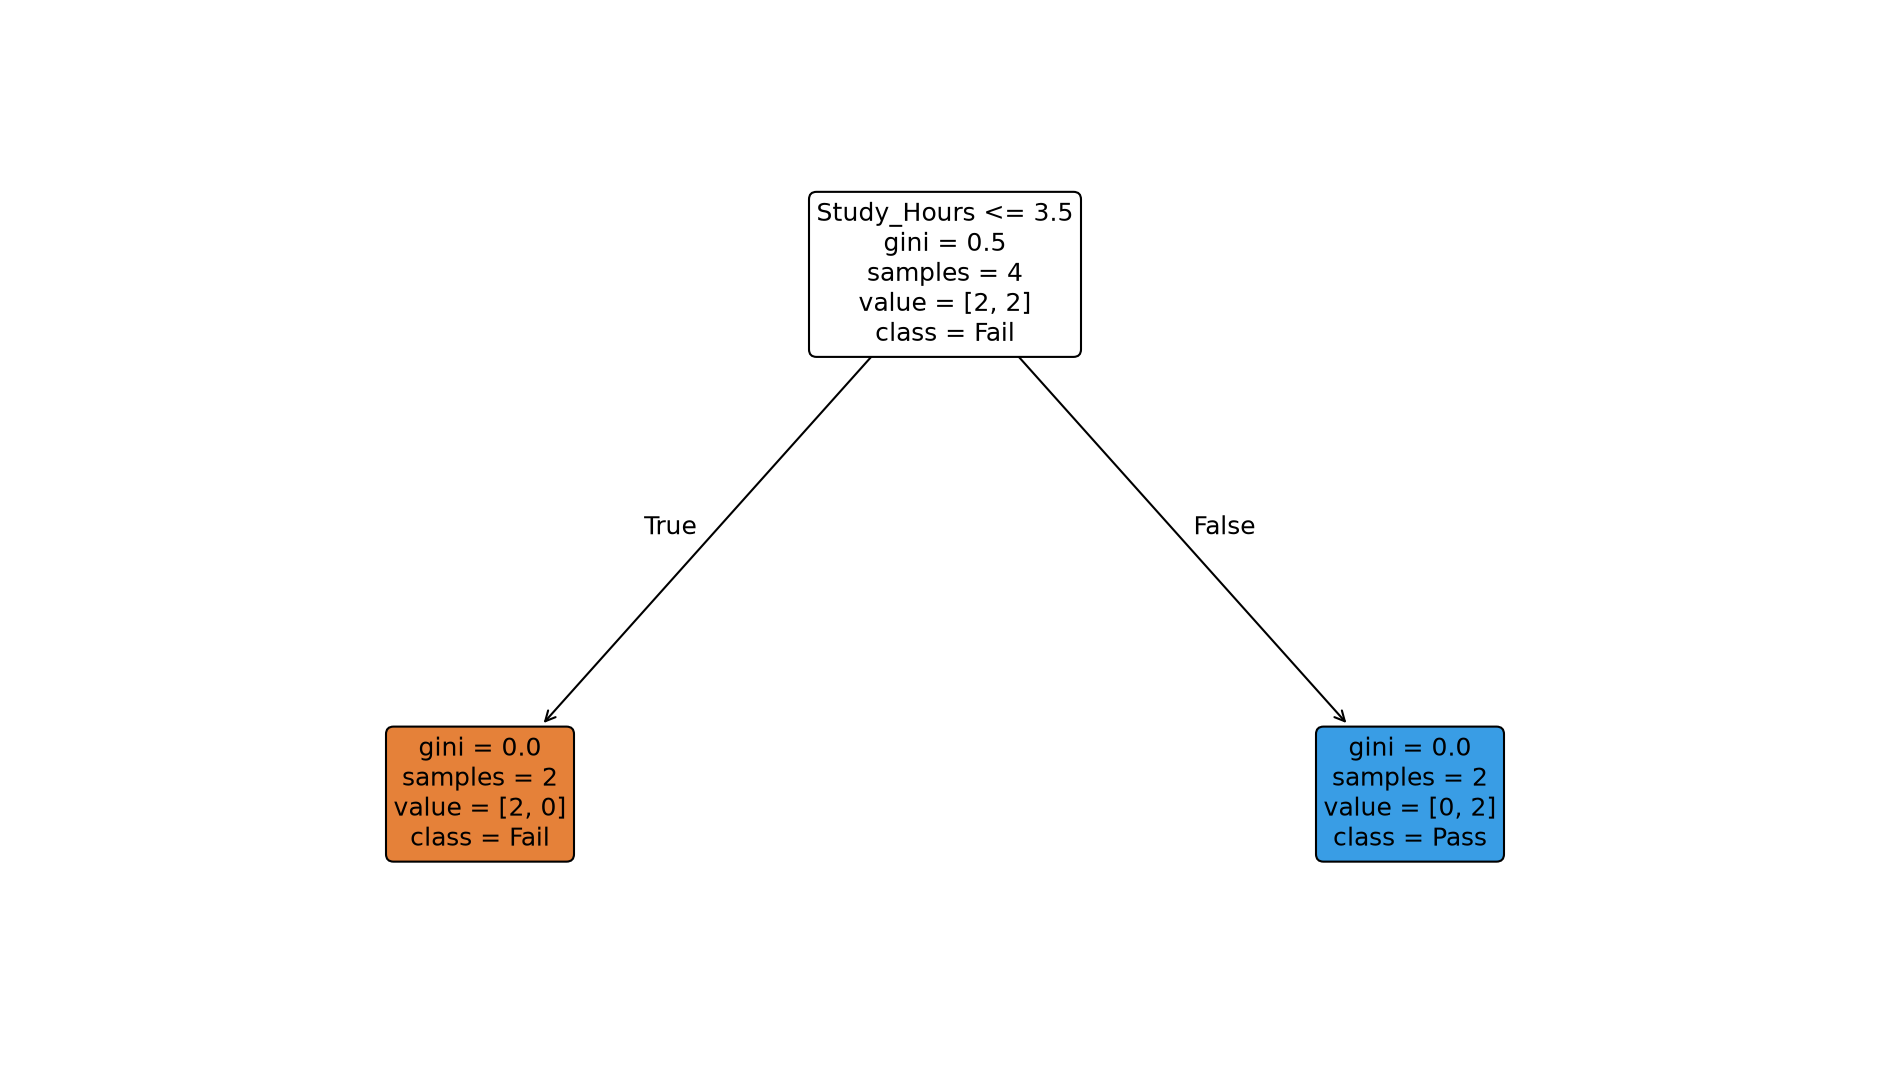

In [12]:
plt.figure(figsize=(16, 9), dpi=150)
plot_tree(
    model,
    feature_names=["Study_Hours", "Attendance"],
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True,
    proportion=False,
    precision=2,
    fontsize=12
)

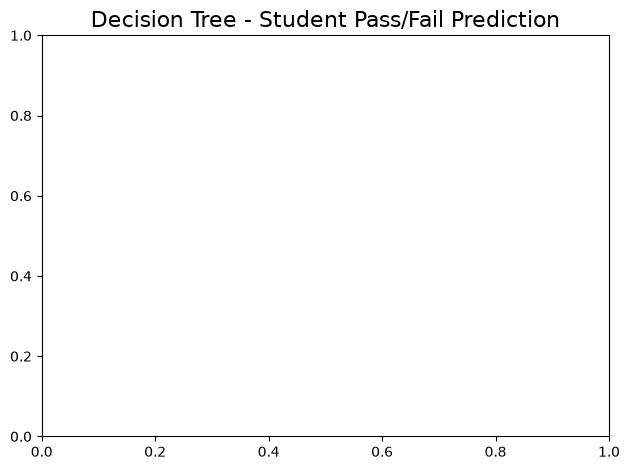

In [13]:
plt.title("Decision Tree - Student Pass/Fail Prediction",fontsize=16)
plt.tight_layout()
plt.show()

In [14]:
y_pred = model.predict(x_test)
print("\nActual Results:")
print(y_test.values)
print("\npredicted results")
print(y_pred)


Actual Results:
<ArrowStringArray>
['Pass', 'Fail']
Length: 2, dtype: str

predicted results
['Pass' 'Fail']


In [15]:
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:",accuracy*100,"%")


Model Accuracy: 100.0 %


In [16]:
cm =confusion_matrix(
    y_test,
    y_pred,
    labels=["Fail","Pass"]
)
print(cm)

[[1 0]
 [0 1]]


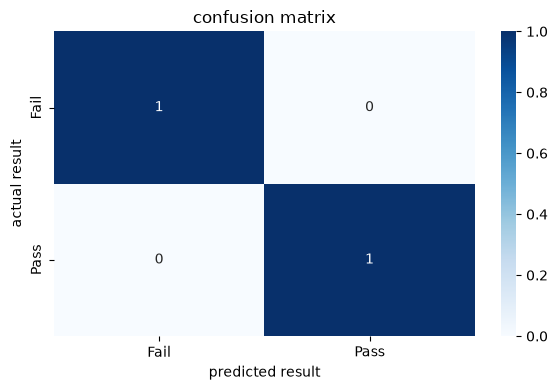

In [17]:
plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("predicted result")
plt.ylabel("actual result")
plt.title("confusion matrix")
plt.tight_layout()
plt.show()

In [18]:
# Step 11: Classification Report
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Fail", "Pass"],
        zero_division=0
    )
)

# Step 12: Predict Result for a New Student
new_student = pd.DataFrame({
    "Study_Hours": [4],
    "Attendance": [85]
})

prediction = model.predict(new_student)

print("\nNew Student Details:")
print(new_student)

print("\nPredicted Student Result:", prediction[0])


Classification Report:
              precision    recall  f1-score   support

        Fail       0.00      0.00      0.00         0
        Pass       0.00      0.00      0.00         0

   micro avg       0.00      0.00      0.00         0
   macro avg       0.00      0.00      0.00         0
weighted avg       0.00      0.00      0.00         0


New Student Details:
   Study_Hours  Attendance
0            4          85

Predicted Student Result: Pass
